# 과적합(Overfitting) 점검 결과 해석 노트북

이 노트북은 강판 결함 분류 모델(`gpt_claude.ipynb`)의 **과적합 점검 결과 CSV 3개**를 불러와서,
초보자도 따라 읽을 수 있도록 한 단계씩 해석합니다.

| 파일 | 무엇을 확인하나 |
|---|---|
| `overfit_learning_curve.csv` | 데이터 양을 늘릴 때 학습 점수와 검증 점수가 어떻게 변하나 |
| `overfit_nested_cv.csv` | 튜닝·모델 선택 과정 자체가 점수를 부풀렸나 (낙관 편향) |
| `overfit_repeated_split.csv` | 테스트셋을 다르게 뽑으면 점수가 얼마나 흔들리나 (분할 운) |

> **사용법**: 이 노트북과 CSV 3개를 같은 폴더에 두고 위에서부터 차례로 실행하세요.

## 0. 먼저 알아둘 개념

**과적합이란?**
시험 공부에 비유하면, 기출문제의 **답을 통째로 외운 학생**과 같습니다.
기출문제(학습 데이터)는 100점이지만, 처음 보는 문제(새 데이터)에서는 점수가 떨어집니다.
그래서 과적합 여부는 "학습 점수가 높은가"가 아니라 **"처음 보는 데이터에서도 점수가 잘 나오는가"**로 판단합니다.

**자주 나오는 용어**

| 용어 | 쉬운 설명 |
|---|---|
| Macro F1 | 7개 결함 종류별 F1 점수를 **단순 평균**한 값. 개수가 적은 결함도 똑같이 중요하게 취급. 1에 가까울수록 좋음 |
| 학습 점수 | 모델이 공부한 데이터로 다시 채점한 점수 (기출문제 점수) |
| 검증 / 테스트 점수 | 모델이 본 적 없는 데이터로 채점한 점수 (실전 점수) |
| 격차 | 학습 점수 − 검증 점수. 클수록 "외운 정도"가 큼 |
| OOF (Out-of-Fold) | 교차검증에서 각 데이터를 **그 데이터를 학습하지 않은 모델**로 예측해 모은 점수. 모델 고를 때 쓴 점수 |
| 낙관 편향 | 모델 고를 때 본 점수(OOF) − 진짜 새 데이터 점수. 양수면 "고를 때 점수가 부풀려졌다" |
| 확률 보정 | 결함 종류별로 확률에 배율을 곱해 Macro F1을 높이려는 후처리 |
| 표준편차(SD) | 값들이 평균에서 얼마나 흩어져 있는지. 클수록 결과가 들쭉날쭉 |
| p-value | "사실 차이가 0인데 우연히 이 정도 차이가 나올 확률". 보통 0.05보다 작으면 '우연이 아니다'라고 봄 |

## 1. 준비: 라이브러리 불러오기와 한글 폰트 설정

In [1]:
# ------------------------------------------------------------
# 필요한 라이브러리 불러오기
# ------------------------------------------------------------
import numpy as np                      # 숫자 계산 (평균, 표준편차 등)
import pandas as pd                     # 표(데이터프레임) 다루기
import matplotlib.pyplot as plt         # 그래프 그리기
from matplotlib import font_manager     # 설치된 폰트 목록 확인용
from scipy import stats                 # 통계 검정 (t-검정 등)

try:
    from IPython.display import display # 표를 예쁘게 출력 (주피터 환경)
except ImportError:
    display = print                     # 주피터가 아니면 그냥 print 사용

# ------------------------------------------------------------
# 한글 폰트 설정 (그래프 제목/축 이름의 한글이 깨지지 않게)
# 운영체제마다 기본 한글 폰트 이름이 다르므로, 있는 것을 차례로 찾아서 사용
# ------------------------------------------------------------
installed = {f.name for f in font_manager.fontManager.ttflist}   # 설치된 폰트 이름들
for font in ["Malgun Gothic",      # 윈도우
             "AppleGothic",        # 맥
             "NanumGothic",        # 리눅스/코랩 (나눔폰트 설치 시)
             "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        print("사용 폰트:", font)
        break
else:
    print("한글 폰트를 찾지 못했습니다. 그래프의 한글이 네모(□)로 보일 수 있습니다.")

plt.rcParams["axes.unicode_minus"] = False   # 한글 폰트에서 마이너스(-) 기호가 깨지는 문제 방지
pd.set_option("display.float_format", "{:.4f}".format)   # 표의 소수점을 4자리로 통일

사용 폰트: Noto Sans CJK JP


In [2]:
# ------------------------------------------------------------
# CSV 3개 불러오기
# encoding="utf-8-sig": 원본 노트북이 이 인코딩으로 저장했기 때문에 한글 열 이름이 깨지지 않음
# ------------------------------------------------------------
lc_raw   = pd.read_csv("overfit_learning_curve.csv", encoding="utf-8-sig")  # 학습 곡선
nested   = pd.read_csv("overfit_nested_cv.csv",      encoding="utf-8-sig")  # 중첩 교차검증
split_df = pd.read_csv("overfit_repeated_split.csv", encoding="utf-8-sig")  # 반복 분할 평가

# 원본 노트북의 최종 테스트 Macro F1 (seed 42 분할). 비교 기준선으로 사용
NOTEBOOK_TEST_F1 = 0.8349

# 각 표의 크기(행, 열) 확인
print("학습 곡선   :", lc_raw.shape)
print("중첩 교차검증:", nested.shape)
print("반복 분할   :", split_df.shape)

학습 곡선   : (30, 5)
중첩 교차검증: (5, 9)
반복 분할   : (10, 7)


## 2. 학습 곡선: "데이터를 늘리면 실전 점수가 오르나?"

**무엇을 했나?**
개발 데이터를 5조각으로 나눠(5-Fold) 1조각은 검증용으로 남기고,
나머지로 학습할 때 학습 데이터 양을 20% → 35% → … → 100%로 늘려가며 점수를 기록했습니다.

**읽는 법**
- 학습 점수와 검증 점수의 **격차가 데이터가 늘수록 줄어들면** 정상입니다.
- 검증 점수가 **끝까지 계속 오르고 있으면** 데이터를 더 모으면 성능이 더 오를 수 있다는 뜻입니다.

In [3]:
# ------------------------------------------------------------
# 데이터 양(frac)별로 5개 fold 결과를 평균 내기
# ------------------------------------------------------------
lc = lc_raw.groupby("frac").agg(
    학습개수=("n_train", "mean"),   # 학습에 쓴 데이터 개수 (fold 평균)
    학습점수=("train", "mean"),     # 학습 데이터로 채점한 Macro F1 평균
    학습SD=("train", "std"),        # 학습 점수의 fold 간 표준편차
    검증점수=("valid", "mean"),     # 검증 데이터로 채점한 Macro F1 평균
    검증SD=("valid", "std"),        # 검증 점수의 fold 간 표준편차
)
lc["격차"] = lc["학습점수"] - lc["검증점수"]          # 과적합 정도를 나타내는 격차
lc["검증점수_증가"] = lc["검증점수"].diff()           # 바로 앞 단계보다 검증 점수가 얼마나 올랐나
lc["학습개수"] = lc["학습개수"].round().astype(int)   # 개수는 정수로 표시
display(lc)

,학습개수,학습점수,학습SD,검증점수,검증SD,격차,검증점수_증가
frac,,,,,,,
0.2000,248,1.0000,0.0000,0.7399,0.0338,0.2601,NaN
0.3500,434,1.0000,0.0000,0.7815,0.0282,0.2185,0.0416
0.5000,621,1.0000,0.0000,0.7986,0.0155,0.2014,0.0171
0.6500,807,1.0000,0.0000,0.8054,0.0247,0.1946,0.0068
0.8000,993,1.0000,0.0000,0.8131,0.0207,0.1869,0.0077
1.0000,1242,1.0000,0.0000,0.8359,0.0177,0.1641,0.0228


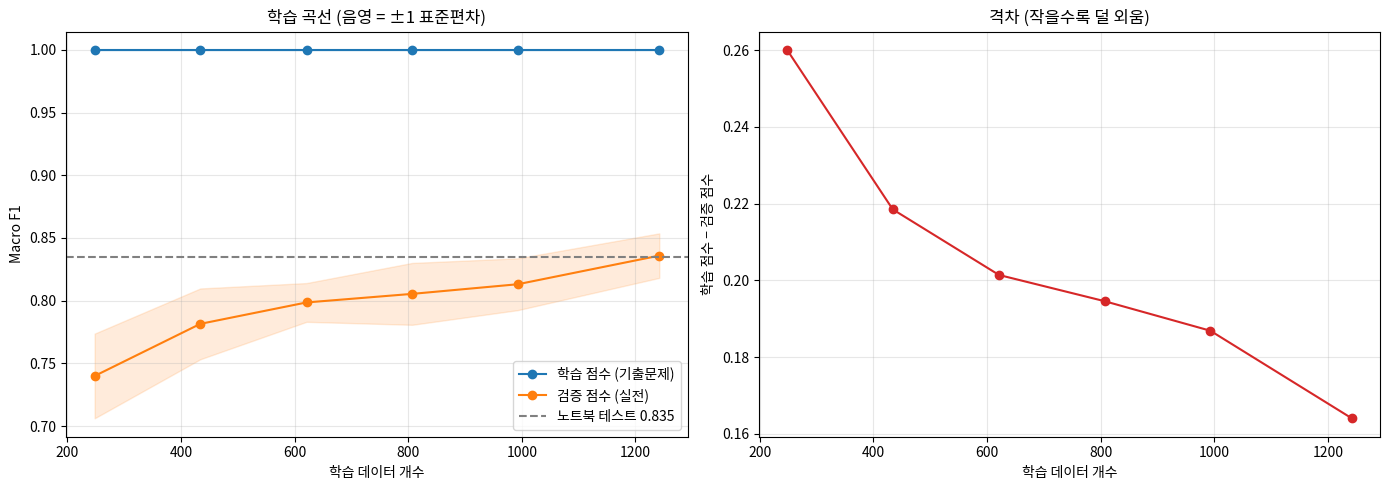

In [4]:
# ------------------------------------------------------------
# 그래프 2개: (왼쪽) 학습/검증 점수 곡선, (오른쪽) 격차
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 왼쪽: 학습 점수(파랑)와 검증 점수(주황). 음영은 ±1 표준편차 범위
for col, sd, color, label in [("학습점수", "학습SD", "tab:blue",   "학습 점수 (기출문제)"),
                              ("검증점수", "검증SD", "tab:orange", "검증 점수 (실전)")]:
    axes[0].plot(lc["학습개수"], lc[col], "o-", color=color, label=label)
    axes[0].fill_between(lc["학습개수"], lc[col] - lc[sd], lc[col] + lc[sd],
                         color=color, alpha=0.15)
# 회색 점선: 원본 노트북의 테스트 점수
axes[0].axhline(NOTEBOOK_TEST_F1, color="gray", ls="--", label=f"노트북 테스트 {NOTEBOOK_TEST_F1:.3f}")
axes[0].set(xlabel="학습 데이터 개수", ylabel="Macro F1", title="학습 곡선 (음영 = ±1 표준편차)")
axes[0].legend(); axes[0].grid(alpha=0.3)

# 오른쪽: 격차(학습 − 검증)가 데이터가 늘수록 줄어드는지
axes[1].plot(lc["학습개수"], lc["격차"], "o-", color="tab:red")
axes[1].set(xlabel="학습 데이터 개수", ylabel="학습 점수 − 검증 점수", title="격차 (작을수록 덜 외움)")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [5]:
# ------------------------------------------------------------
# 핵심 숫자를 자동으로 뽑아 문장으로 출력
# ------------------------------------------------------------
first, last = lc.iloc[0], lc.iloc[-1]   # 가장 적은 데이터 / 가장 많은 데이터 행

print(f"학습 점수      : 모든 단계에서 {lc['학습점수'].min():.3f} ~ {lc['학습점수'].max():.3f}")
print(f"검증 점수      : {first['검증점수']:.3f} ({int(first['학습개수'])}개) → {last['검증점수']:.3f} ({int(last['학습개수'])}개)")
print(f"격차           : {first['격차']:.3f} → {last['격차']:.3f}")
print(f"마지막 구간 증가: {last['검증점수_증가']:+.3f}")

# 마지막 구간에서도 검증 점수가 0.01 이상 오르면 '아직 정체되지 않음'으로 판단 (간단한 기준)
if last["검증점수_증가"] > 0.01:
    print("→ 검증 점수가 아직 오르는 중: 데이터를 더 모으면 성능이 더 오를 가능성이 있음")
else:
    print("→ 검증 점수가 거의 정체: 데이터를 더 모아도 큰 개선은 기대하기 어려움")

학습 점수      : 모든 단계에서 1.000 ~ 1.000
검증 점수      : 0.740 (248개) → 0.836 (1242개)
격차           : 0.260 → 0.164
마지막 구간 증가: +0.023
→ 검증 점수가 아직 오르는 중: 데이터를 더 모으면 성능이 더 오를 가능성이 있음


### 해석

**① 학습 점수가 항상 1.0 (만점)**
모델이 학습 데이터를 **완벽하게 외우고 있다**는 뜻입니다. 겉으로 보면 과적합 같지만,
이 모델에 쓰인 Extra Trees·LightGBM 같은 트리 앙상블은 원래 학습 데이터를 거의 다 맞히는 경우가 흔합니다.
그래서 학습 점수 1.0 자체는 경고 신호가 아니고, **검증 점수가 어떻게 되는지**를 봐야 합니다.

**② 격차가 0.26 → 0.16으로 감소**
격차가 줄어든 이유는 학습 점수가 내려와서가 아니라 **검증 점수가 올라와서**입니다.
데이터가 많아질수록 "외운 것"이 "이해한 것"에 가까워지고 있다는 좋은 신호입니다.

**③ 검증 점수가 끝까지 상승 (0.740 → 0.836, 마지막 구간에서도 +0.023)**
곡선이 아직 평평해지지 않았습니다. 즉 이 모델은 **데이터가 부족한 쪽**에 있으며,
데이터를 더 모으면 성능이 더 오를 여지가 있습니다.

> **주의할 점**: 여기서 쓴 하이퍼파라미터는 개발 데이터 전체로 미리 튜닝한 값이라,
> 검증 점수가 아주 약간 유리하게 나왔을 수 있습니다. 그 정도가 얼마인지는 다음 단계(중첩 교차검증)에서 확인합니다.

## 3. 중첩 교차검증: "모델을 고르는 과정이 점수를 부풀렸나?"

**왜 필요한가?**
모델을 튜닝하고, 여러 후보 중 가장 좋은 것을 고르고, 확률 보정 배율을 찾는 과정은 모두 **같은 OOF 점수**를 보고 결정했습니다.
여러 번 시도해서 가장 좋은 것을 고르면, 그 점수는 우연히 운이 좋았던 몫까지 포함해 **부풀려지기 쉽습니다**.
(시험지 10장 중 가장 잘 본 1장의 점수를 내 실력이라고 말하는 것과 비슷합니다.)

**무엇을 했나?**
전체 데이터를 바깥 5조각으로 나눠, 1조각은 **완전히 숨겨두고** 나머지로 튜닝→후보 선택→보정을 처음부터 다시 했습니다.
그다음 숨겨둔 조각으로 채점합니다.

**읽는 법**
- **낙관 편향 = 안쪽 OOF − 바깥 평가 점수**. 0에 가까우면 선택 과정이 점수를 부풀리지 않았다는 뜻.
- **보정 효과 = 보정 포함 점수 − 보정 없는 점수**. 대부분 양수면 보정이 새 데이터에서도 도움이 된다는 뜻.

In [6]:
# ------------------------------------------------------------
# 중첩 교차검증 결과 표와 요약 통계
# ------------------------------------------------------------
nested = nested.set_index("Fold")   # Fold 번호를 행 이름으로
display(nested)

# 숫자 열만 골라 평균/표준편차/최소/최대 계산
num_cols = ["안쪽 OOF", "평가 Macro F1", "평가 Macro F1 (보정 없음)", "낙관 편향", "보정 효과"]
display(nested[num_cols].agg(["mean", "std", "min", "max"]))

,선택 후보,보정,안쪽 OOF,평가 Macro F1,평가 Macro F1 (보정 없음),평가 Accuracy,낙관 편향,보정 효과
Fold,,,,,,,,
1,앙상블(상위 3),True,0.8363,0.8429,0.8428,0.8123,-0.0067,0.0001
2,앙상블(전체 4),True,0.8429,0.8289,0.8181,0.8093,0.0141,0.0108
3,앙상블(상위 2),True,0.8305,0.7877,0.7915,0.7603,0.0428,-0.0039
4,앙상블(상위 2),True,0.8299,0.8588,0.8620,0.8247,-0.0289,-0.0032
5,앙상블(상위 2),True,0.8422,0.8257,0.8436,0.7990,0.0165,-0.0179


,안쪽 OOF,평가 Macro F1,평가 Macro F1 (보정 없음),낙관 편향,보정 효과
mean,0.8363,0.8288,0.8316,0.0076,-0.0028
std,0.0062,0.0265,0.0273,0.0269,0.0103
min,0.8299,0.7877,0.7915,-0.0289,-0.0179
max,0.8429,0.8588,0.8620,0.0428,0.0108


In [7]:
# ------------------------------------------------------------
# 낙관 편향과 보정 효과가 '0과 다르다'고 말할 수 있는지 통계 검정
# 단일표본 t-검정: "평균이 0이다"라는 가정을 검정
#   p-value가 0.05보다 크면 → 0과 구별할 수 없음 (우연 수준의 차이)
# ------------------------------------------------------------
def check_zero(series, name):
    # 평균, 양수 개수, p-value를 한 줄로 출력하는 도우미 함수
    p = stats.ttest_1samp(series, 0).pvalue
    print(f"{name:<8}: 평균 {series.mean():+.4f} | 표준편차 {series.std():.4f} | "
          f"양수 {(series > 0).sum()}/{len(series)}개 | p-value {p:.3f}")

check_zero(nested["낙관 편향"], "낙관 편향")
check_zero(nested["보정 효과"], "보정 효과")

# fold가 5개뿐이라 작은 차이는 검출이 어려움. 평균의 오차 범위(약 ±2 x 표준오차)를 참고로 출력
se = nested["낙관 편향"].std() / np.sqrt(len(nested))   # 표준오차 = 표준편차 / √(개수)
print(f"\n참고: 낙관 편향 평균의 오차 범위 ≈ ±{2 * se:.3f} → 이보다 작은 편향은 이 실험으로 판별 불가")

# fold마다 어떤 후보가 선택됐는지 개수 세기
print("\n[fold별 선택 후보]")
print(nested["선택 후보"].value_counts().to_string())

낙관 편향   : 평균 +0.0076 | 표준편차 0.0269 | 양수 3/5개 | p-value 0.564
보정 효과   : 평균 -0.0028 | 표준편차 0.0103 | 양수 2/5개 | p-value 0.573

참고: 낙관 편향 평균의 오차 범위 ≈ ±0.024 → 이보다 작은 편향은 이 실험으로 판별 불가

[fold별 선택 후보]
선택 후보
앙상블(상위 2)    3
앙상블(상위 3)    1
앙상블(전체 4)    1


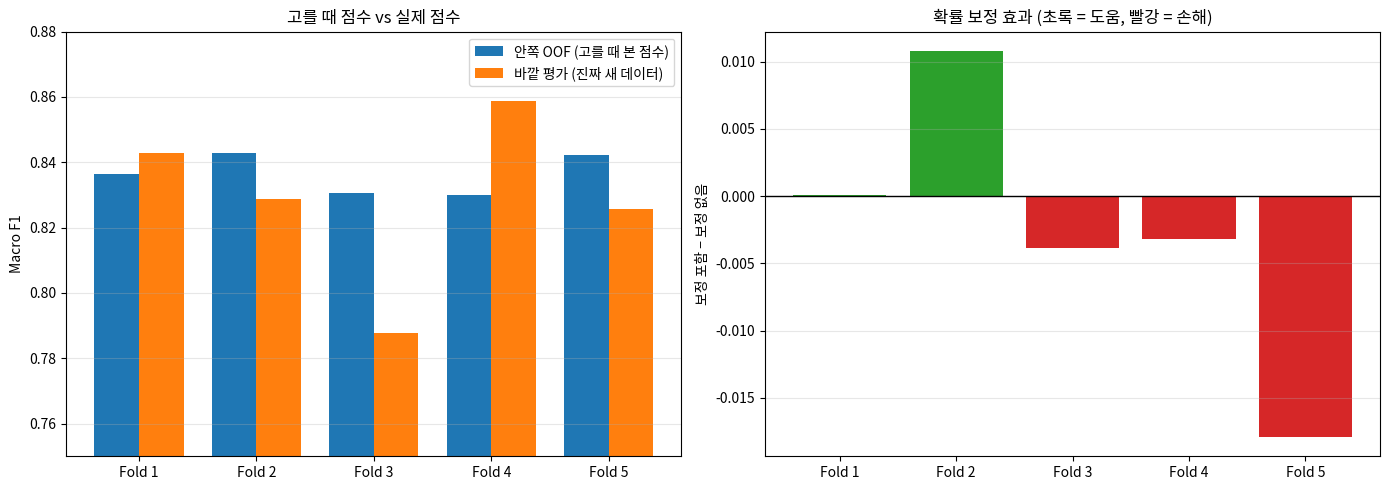

In [8]:
# ------------------------------------------------------------
# 그래프 2개: (왼쪽) fold별 OOF vs 실제 평가 점수, (오른쪽) fold별 보정 효과
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(nested))   # 막대 위치 (0, 1, 2, 3, 4)
w = 0.38                     # 막대 너비

# 왼쪽: 두 막대 높이가 비슷하면 선택 과정이 점수를 부풀리지 않은 것
axes[0].bar(x - w/2, nested["안쪽 OOF"],      w, label="안쪽 OOF (고를 때 본 점수)")
axes[0].bar(x + w/2, nested["평가 Macro F1"], w, label="바깥 평가 (진짜 새 데이터)")
axes[0].set_xticks(x, [f"Fold {i}" for i in nested.index])
axes[0].set_ylim(0.75, 0.88)   # 차이가 잘 보이도록 y축 범위를 좁힘
axes[0].set(ylabel="Macro F1", title="고를 때 점수 vs 실제 점수")
axes[0].legend(); axes[0].grid(alpha=0.3, axis="y")

# 오른쪽: 초록(양수) = 보정이 도움, 빨강(음수) = 보정이 오히려 손해
colors = ["tab:green" if v > 0 else "tab:red" for v in nested["보정 효과"]]
axes[1].bar(x, nested["보정 효과"], color=colors)
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xticks(x, [f"Fold {i}" for i in nested.index])
axes[1].set(ylabel="보정 포함 − 보정 없음", title="확률 보정 효과 (초록 = 도움, 빨강 = 손해)")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout(); plt.show()

### 해석

**① 낙관 편향 평균 +0.0076 → 선택 과정의 과적합은 작다**
모델을 고를 때 본 점수(0.836)와 진짜 새 데이터 점수(0.829)의 차이가 1%p도 안 됩니다.
5개 중 3개 fold만 양수이고 p-value도 0.56으로 커서, **우연 수준의 차이**로 볼 수 있습니다.
다만 fold가 5개뿐이라 약 ±0.024보다 작은 편향은 이 실험만으로 확실히 판별할 수 없습니다.

**② fold마다 바깥 점수가 0.788 ~ 0.859로 흔들림**
같은 방법으로 만들어도 **어떤 데이터로 평가하느냐에 따라** 점수가 7%p 정도 오르내립니다.
점수 하나만 보고 "이 모델은 0.835짜리다"라고 단정하면 안 되는 이유입니다.

**③ 선택되는 후보가 fold마다 다름 (상위 2, 상위 3, 전체 4)**
앙상블 후보들의 성능이 **사실상 비슷해서** 어느 것이 뽑히든 우연에 가깝다는 뜻입니다.
어느 앙상블을 쓰든 결과는 크게 다르지 않습니다.

**④ 보정 효과 평균 −0.0028, 5개 중 2개만 양수**
중첩 교차검증 기준으로는 **확률 보정이 새 데이터에서 도움이 된다는 근거가 없습니다.**

## 4. 반복 분할 평가: "테스트셋을 다르게 뽑으면 점수가 얼마나 흔들리나?"

**왜 필요한가?**
원본 노트북은 테스트셋을 딱 한 번(seed 42) 뽑았습니다. 그 한 번이 **운 좋게 쉬운 문제**였을 수도 있습니다.

**무엇을 했나?**
테스트셋 분할을 10가지(seed 10개)로 바꿔가며 전체 과정을 매번 처음부터 반복했습니다.
seed 42는 원본 노트북과 같은 분할이므로 노트북 점수(0.8349)와 같게 나와야 합니다(재현 확인).

**읽는 법**
- 10개 점수의 **평균**이 "실제로 기대할 수 있는 점수"입니다.
- **표준편차**가 "분할 운에 따른 흔들림 정도"입니다.

In [9]:
# ------------------------------------------------------------
# 반복 분할 결과 표와 요약 통계
# ------------------------------------------------------------
split_df = split_df.set_index("seed")
# 각 seed에서 보정이 준 효과를 새 열로 추가
split_df["보정 효과"] = split_df["평가 Macro F1"] - split_df["평가 Macro F1 (보정 없음)"]
display(split_df)

display(split_df.drop(columns="선택 후보").agg(["mean", "std", "min", "max"]))

,선택 후보,OOF,평가 Macro F1,평가 Macro F1 (보정 없음),평가 Accuracy,OOF - 테스트,보정 효과
seed,,,,,,,
42,앙상블(상위 2),0.8358,0.8349,0.8264,0.8201,0.0009,0.0085
1,앙상블(상위 3),0.8361,0.8295,0.8163,0.8329,0.0066,0.0132
2,앙상블(상위 2),0.8500,0.8430,0.8371,0.8021,0.0069,0.0060
3,앙상블(상위 3),0.8413,0.8146,0.8176,0.8046,0.0267,-0.0030
4,앙상블(상위 3),0.8360,0.8092,0.8020,0.7738,0.0268,0.0071
5,앙상블(상위 3),0.8265,0.8216,0.8173,0.7969,0.0049,0.0043
6,앙상블(상위 3),0.8376,0.8647,0.8550,0.8303,-0.0272,0.0097
7,앙상블(상위 3),0.8428,0.8121,0.8143,0.7918,0.0307,-0.0022
8,앙상블(전체 4),0.8495,0.8147,0.8219,0.7918,0.0347,-0.0071


,OOF,평가 Macro F1,평가 Macro F1 (보정 없음),평가 Accuracy,OOF - 테스트,보정 효과
mean,0.8386,0.8292,0.8250,0.8067,0.0094,0.0042
std,0.0075,0.0183,0.0155,0.0192,0.0207,0.0064
min,0.8265,0.8092,0.8020,0.7738,-0.0272,-0.0071
max,0.8500,0.8647,0.8550,0.8329,0.0347,0.0132


In [10]:
# ------------------------------------------------------------
# 핵심 숫자 계산
# ------------------------------------------------------------
test = split_df["평가 Macro F1"]

# (1) 재현 확인: seed 42 점수가 노트북 점수와 같은지
print(f"[재현 확인] seed 42 = {test.loc[42]:.4f} / 노트북 = {NOTEBOOK_TEST_F1:.4f}")

# (2) 기대 성능과 흔들림
print(f"[기대 성능] 평균 {test.mean():.4f} ± {test.std():.4f}  (범위 {test.min():.4f} ~ {test.max():.4f})")

# (3) 노트북 점수가 10개 중 몇 등인지 (1등 = 가장 높음)
rank = int((test > test.loc[42]).sum()) + 1
print(f"[노트북 순위] 10개 중 {rank}등, 평균보다 {test.loc[42] - test.mean():+.4f}")

# (4) OOF − 테스트 차이(낙관 편향과 같은 의미)가 0과 다른지
check_zero(split_df["OOF - 테스트"], "OOF-테스트")

# (5) 보정 효과
check_zero(split_df["보정 효과"], "보정 효과")

# (6) OOF 점수가 높은 seed가 테스트 점수도 높은가? (상관계수: -1 ~ 1, 0에 가까우면 관계 없음)
r = np.corrcoef(split_df["OOF"], test)[0, 1]
print(f"[OOF와 테스트 점수 상관계수] {r:+.2f}")

[재현 확인] seed 42 = 0.8349 / 노트북 = 0.8349
[기대 성능] 평균 0.8292 ± 0.0183  (범위 0.8092 ~ 0.8647)
[노트북 순위] 10개 중 4등, 평균보다 +0.0057
OOF-테스트 : 평균 +0.0094 | 표준편차 0.0207 | 양수 8/10개 | p-value 0.185
보정 효과   : 평균 +0.0042 | 표준편차 0.0064 | 양수 7/10개 | p-value 0.065
[OOF와 테스트 점수 상관계수] -0.14


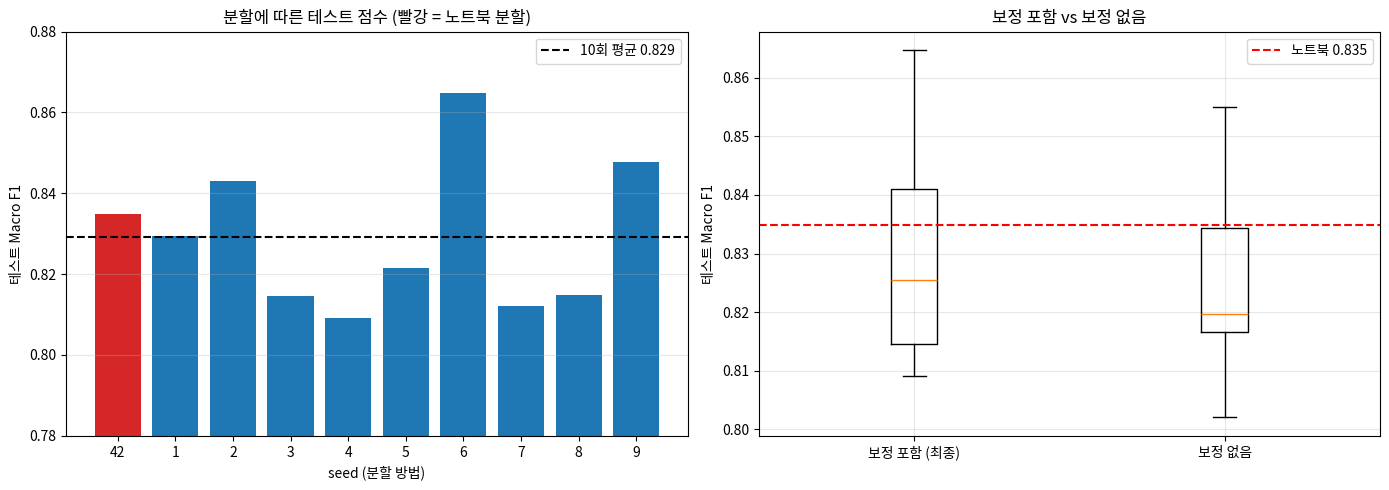

In [11]:
# ------------------------------------------------------------
# 그래프 2개: (왼쪽) seed별 테스트 점수, (오른쪽) 보정 포함/없음 상자그림
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 왼쪽: seed별 점수 막대. seed 42(노트북)는 빨간색으로 강조
labels = [str(s) for s in split_df.index]
colors = ["tab:red" if s == 42 else "tab:blue" for s in split_df.index]
axes[0].bar(labels, test, color=colors)
axes[0].axhline(test.mean(), color="black", ls="--", label=f"10회 평균 {test.mean():.3f}")
axes[0].set_ylim(0.78, 0.88)
axes[0].set(xlabel="seed (분할 방법)", ylabel="테스트 Macro F1",
            title="분할에 따른 테스트 점수 (빨강 = 노트북 분할)")
axes[0].legend(); axes[0].grid(alpha=0.3, axis="y")

# 오른쪽: 상자그림. 상자 = 가운데 50% 범위, 가운데 선 = 중앙값
axes[1].boxplot([test, split_df["평가 Macro F1 (보정 없음)"]])
axes[1].set_xticks([1, 2], ["보정 포함 (최종)", "보정 없음"])
axes[1].axhline(NOTEBOOK_TEST_F1, color="red", ls="--", label=f"노트북 {NOTEBOOK_TEST_F1:.3f}")
axes[1].set(ylabel="테스트 Macro F1", title="보정 포함 vs 보정 없음")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

### 해석

**① 재현 확인 통과**
seed 42 점수가 노트북 점수와 정확히 같아서, 점검 코드가 원본과 같은 과정을 제대로 반복했다는 것이 확인됩니다.

**② 실제 기대 성능은 약 0.83 ± 0.02**
10번의 평균은 0.829이고, 분할에 따라 0.809 ~ 0.865 사이에서 움직입니다.
노트북의 0.8349는 10개 중 4등으로 **평균보다 조금 운이 좋은 분할**이었습니다.
그래서 성능을 보고할 때는 0.835보다 **"약 0.83 (±0.02)"** 이 더 정직한 표현입니다.

**③ OOF − 테스트 평균 +0.009 → 약간 낙관적이지만 의미 있는 차이는 아님**
10번 중 8번은 OOF가 테스트보다 높아서 약간 부풀려지는 경향은 있지만, p-value가 0.19로 우연과 구별되지 않습니다.
중첩 교차검증 결과(+0.0076)와도 비슷해, **선택 과정의 과적합은 약 0.01 이내**라고 정리할 수 있습니다.

**④ OOF와 테스트 점수 사이에 관계가 거의 없음 (상관계수 약 −0.14)**
OOF가 높았던 seed라고 테스트도 높은 것이 아닙니다. 테스트 점수가 흔들리는 주된 이유는 모델이 달라서가 아니라
**389개뿐인 테스트셋을 어떻게 뽑았느냐**(특히 Dirtiness 11개, Stains 14개처럼 개수가 적은 결함)이기 때문입니다.

**⑤ 보정 효과 평균 +0.004, 10번 중 7번 양수**
여기서는 보정이 약간 도움이 되는 쪽이지만 p-value가 0.065로 확실하지 않고, 중첩 교차검증과는 **방향이 반대**입니다.

## 5. 확률 보정 효과 종합

두 실험에서 보정 효과의 방향이 엇갈렸으므로, 15번의 결과를 합쳐서 판단합니다.

In [12]:
# ------------------------------------------------------------
# 중첩 CV 5회 + 반복 분할 10회 = 15회의 보정 효과를 합쳐서 평가
# ------------------------------------------------------------
all_effect = pd.concat([nested["보정 효과"], split_df["보정 효과"]], ignore_index=True)
check_zero(all_effect, "보정(15회)")

# 원본 노트북의 OOF에서 보정으로 얻은 점수 상승 (노트북 출력값: 0.8236 → 0.8358)
oof_gain = 0.8358 - 0.8236
print(f"\n노트북 OOF에서 보였던 보정 이득 : {oof_gain:+.4f}")
print(f"새 데이터에서 실제로 얻은 이득   : {all_effect.mean():+.4f}")
print(f"→ OOF 이득 중 실제로 재현된 비율 : 약 {all_effect.mean() / oof_gain:.0%}")

보정(15회) : 평균 +0.0019 | 표준편차 0.0083 | 양수 9/15개 | p-value 0.393

노트북 OOF에서 보였던 보정 이득 : +0.0122
새 데이터에서 실제로 얻은 이득   : +0.0019
→ OOF 이득 중 실제로 재현된 비율 : 약 15%


### 해석

노트북에서는 보정으로 OOF 점수가 **+0.012** 올랐지만, 새 데이터에서 실제로 얻은 이득은 평균 **약 +0.002**로
대부분 재현되지 않았습니다.

이유는 보정 배율을 **OOF 점수를 최대로 만드는 값으로 찾고, 같은 OOF 점수로 다시 평가했기 때문**입니다.
문제를 보고 답을 맞춘 다음 같은 문제로 채점한 셈이라 점수가 부풀려집니다.
앞에서 본 약 0.01의 낙관 편향도 **상당 부분이 이 보정 단계에서 온 것**으로 보입니다.

원본 노트북은 OOF 이득이 0.005 이상일 때만 보정을 쓰도록 했는데,
실제 이득(약 0.002)은 이 기준보다 작습니다. 즉 **보정은 써도 되고 안 써도 되는 수준**입니다.

## 6. 최종 요약

In [13]:
# ------------------------------------------------------------
# 지금까지의 핵심 숫자를 한 표로 정리
# ------------------------------------------------------------
summary = pd.DataFrame({
    "값": [
        lc["학습점수"].iloc[-1],
        lc["검증점수"].iloc[-1],
        lc["격차"].iloc[-1],
        nested["낙관 편향"].mean(),
        split_df["OOF - 테스트"].mean(),
        test.mean(),
        test.std(),
        NOTEBOOK_TEST_F1,
        all_effect.mean(),
    ],
    "의미": [
        "학습 데이터 점수 (만점 = 다 외움)",
        "검증 점수 (데이터 100% 사용 시)",
        "학습 − 검증 격차",
        "중첩 CV: 고를 때 점수가 부풀려진 정도",
        "반복 분할: 고를 때 점수가 부풀려진 정도",
        "실제 기대 테스트 점수 (10회 평균)",
        "분할 운에 따른 흔들림 (표준편차)",
        "원본 노트북 테스트 점수 (seed 42)",
        "확률 보정의 실제 효과 (15회 평균)",
    ],
}, index=["학습 점수", "검증 점수", "격차", "낙관 편향(중첩)", "낙관 편향(반복)",
          "기대 성능", "흔들림", "노트북 점수", "보정 효과"])
display(summary)

,값,의미
학습 점수,1.0000,학습 데이터 점수 (만점 = 다 외움)
검증 점수,0.8359,검증 점수 (데이터 100% 사용 시)
격차,0.1641,학습 − 검증 격차
낙관 편향(중첩),0.0076,중첩 CV: 고를 때 점수가 부풀려진 정도
낙관 편향(반복),0.0094,반복 분할: 고를 때 점수가 부풀려진 정도
기대 성능,0.8292,실제 기대 테스트 점수 (10회 평균)
흔들림,0.0183,분할 운에 따른 흔들림 (표준편차)
노트북 점수,0.8349,원본 노트북 테스트 점수 (seed 42)
보정 효과,0.0019,확률 보정의 실제 효과 (15회 평균)


### 결론: 과적합이 있는가?

| 질문 | 답 | 근거 |
|---|---|---|
| 모델이 학습 데이터를 외우고 있나? | **예** | 학습 점수 항상 1.0 |
| 그 때문에 새 데이터 성능이 나쁜가? | **아니오** | 검증·테스트 점수 약 0.83으로 안정적 |
| 튜닝·선택 과정이 점수를 부풀렸나? | **조금 (약 0.01)** | 낙관 편향 +0.008 ~ +0.009, 통계적으로 유의하지 않음 |
| 노트북 점수 0.8349를 믿어도 되나? | **약간 운이 좋은 값** | 10회 평균 0.829, 10개 중 4등 |
| 확률 보정은 효과가 있나? | **거의 없음** | OOF 이득 +0.012 → 실제 이득 약 +0.002 |
| 데이터를 더 모으면 좋아질까? | **그럴 가능성 높음** | 검증 점수가 끝까지 상승 중 |

**한 줄 요약**: 모델은 학습 데이터를 외우는 경향이 있지만 실전 성능을 해치는 수준의 과적합은 아니며,
실제로 기대할 수 있는 성능은 **Macro F1 약 0.83 (±0.02)** 입니다.

### 다음에 해볼 수 있는 것

1. **성능 보고 방식 바꾸기**: 단일 점수 0.8349 대신 "약 0.83 (분할에 따라 ±0.02)"로 보고합니다.
2. **보정 단순화 검토**: 효과가 불확실하므로 보정을 빼거나, 단순한 쪽(보정 없음)을 기본으로 두는 것도 합리적입니다.
3. **앙상블 구성 고정**: 후보 간 차이가 없으므로 가벼운 구성(상위 2개)으로 고정해도 손해가 거의 없습니다.
4. **데이터 추가**: 학습 곡선이 아직 오르는 중이라 가장 확실한 성능 개선 방법입니다.
5. **규제 실험(선택)**: `min_samples_leaf`를 키우는 등으로 외우는 정도를 줄일 수 있지만,
   학습 점수가 내려가는 것과 검증 점수가 오르는 것은 별개이므로 실험으로 확인해야 합니다.